# TP - Qualité des données : valeurs manquantes
## Spaceship Titanic

**Durée indicative : 1 h 30**

### Objectifs

À partir d'un jeu de données volontairement détérioré, l'objectif est de :

1. quantifier et visualiser les valeurs manquantes ;
2. étudier leurs motifs ;
3. rechercher des indices permettant de suspecter un mécanisme **MCAR**, **MAR** ou **MNAR** ;
4. choisir des stratégies de traitement simples et adaptées ;
5. vérifier qu'une imputation ne signifie pas nécessairement que la qualité des données est restaurée.


## 0. Contexte

Le vaisseau *Spaceship Titanic* transporte plusieurs milliers de passagers.

À la suite de différents problèmes de collecte, certaines informations sont absentes.  
Trois variables sont concernées :

- `HomePlanet` ;
- `CryoSleep` ;
- `RoomService`.

Votre mission consiste à **diagnostiquer la structure des valeurs manquantes avant de les traiter**.

Les autres colonnes utiles sont notamment :

- `Age` : âge du passager ;
- `Deck` / `CabinSide` : localisation de la cabine ;
- `VIP` : statut VIP ;
- `FoodCourt`, `Spa` : dépenses à bord ;

## 1. Chargement et première exploration

In [26]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression

pd.set_option("display.max_columns", None)

DATA_PATH = Path("../data/spaceship_titanic_missing.csv")

df = pd.read_csv(DATA_PATH)

print("Dimensions :", df.shape)
display(df.head())

Dimensions : (4000, 11)


,PassengerId,HomePlanet,CryoSleep,Deck,CabinSide,Destination,Age,VIP,RoomService,FoodCourt,Spa
0,0001_01,Europa,False,B,P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0
1,0007_01,Earth,False,F,S,TRAPPIST-1e,35.0,False,0.0,785.0,216.0
2,0009_01,Mars,False,F,P,TRAPPIST-1e,32.0,False,73.0,0.0,0.0
3,0011_01,Earth,False,F,P,TRAPPIST-1e,28.0,False,8.0,974.0,2.0
4,0014_01,Mars,False,F,P,55 Cancri e,27.0,False,NaN,122.0,0.0


### Exercice 1 — Comprendre le dataset

1. Affichez les types des variables.
2. Vérifiez l'unicité de `PassengerId`.
3. Affichez quelques statistiques descriptives sur les variables numériques.
4. Identifiez les variables qui contiennent des valeurs manquantes.

In [27]:
df.dtypes

PassengerId        str
HomePlanet         str
CryoSleep       object
Deck               str
CabinSide          str
Destination        str
Age            float64
VIP               bool
RoomService    float64
FoodCourt      float64
Spa            float64
dtype: object

In [28]:
df["PassengerId"].is_unique

True

In [29]:
df.describe()

,Age,RoomService,FoodCourt,Spa
count,4000.000000,3720.000000,4000.000000,4000.000000
mean,28.910250,185.132796,479.952250,305.746500
std,14.720135,563.364488,1640.397025,1108.273136
min,0.000000,0.000000,0.000000,0.000000
25%,19.000000,0.000000,0.000000,0.000000
50%,27.000000,0.000000,0.000000,0.000000
75%,38.000000,13.000000,83.000000,59.000000
max,79.000000,8142.000000,27723.000000,18572.000000


In [30]:
df.isna().sum()

PassengerId      0
HomePlanet     200
CryoSleep      320
Deck             0
CabinSide        0
Destination      0
Age              0
VIP              0
RoomService    280
FoodCourt        0
Spa              0
dtype: int64

On a donc HomePlanet, CryoSleep et RoomService qui présente des valeurs manquantes

## 2. Quantifier les valeurs manquantes

Avant toute correction, on mesure l'ampleur du problème.

### Exercice 2

Construisez un tableau contenant, pour chaque variable :

- le nombre de valeurs manquantes ;
- le pourcentage de valeurs manquantes.

Ne conservez que les variables concernées et triez-les par pourcentage décroissant.

In [31]:
bilan = pd.DataFrame({
    "nombre_manquant": df.isna().sum(),
    "pourcentage_manquant": df.isna().sum() / len(df) * 100
})

display(bilan)

,nombre_manquant,pourcentage_manquant
PassengerId,0,0.0
HomePlanet,200,5.0
CryoSleep,320,8.0
Deck,0,0.0
CabinSide,0,0.0
Destination,0,0.0
Age,0,0.0
VIP,0,0.0
RoomService,280,7.0
FoodCourt,0,0.0


In [32]:
bilan = bilan[bilan["nombre_manquant"] > 0]
bilan = bilan.sort_values("pourcentage_manquant", ascending=False)

display(bilan)

,nombre_manquant,pourcentage_manquant
CryoSleep,320,8.0
RoomService,280,7.0
HomePlanet,200,5.0


### Exercice 3 — Combien de lignes sont réellement concernées ?

Calculez :

- le nombre de lignes incomplètes ;
- leur proportion dans le dataset ;
- le nombre total de valeurs manquantes ;
- le nombre de valeurs manquantes par ligne.

In [33]:
manquants_par_ligne = df.isna().sum(axis=1)

display(manquants_par_ligne)

0       0
1       0
2       0
3       0
4       1
       ..
3995    1
3996    0
3997    0
3998    0
3999    0
Length: 4000, dtype: int64

In [34]:
nombre_lignes_incompletes = (manquants_par_ligne > 0).sum()

print("Nombre de lignes incomplètes :", nombre_lignes_incompletes)

Nombre de lignes incomplètes : 756


In [35]:
pourcentage_lignes_incompletes = nombre_lignes_incompletes / len(df) * 100
total_manquants = manquants_par_ligne.sum()

print("Pourcentage de lignes incomplètes :", pourcentage_lignes_incompletes, "%")
print("Nombre total de valeurs manquantes :", total_manquants)

Pourcentage de lignes incomplètes : 18.9 %
Nombre total de valeurs manquantes : 800


## 3. Visualiser les valeurs manquantes

### Exercice 4

Représentez le pourcentage de valeurs manquantes par variable avec un diagramme en barres.

Le but n'est pas de produire une visualisation complexe : on veut simplement voir immédiatement quelles variables sont concernées.

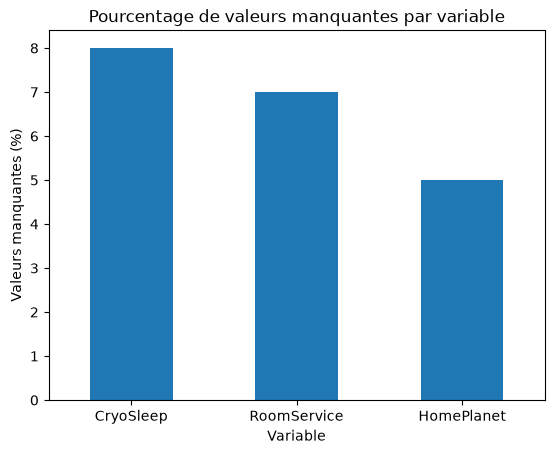

In [36]:
bilan["pourcentage_manquant"].plot(kind="bar")

plt.title("Pourcentage de valeurs manquantes par variable")
plt.xlabel("Variable")
plt.ylabel("Valeurs manquantes (%)")
plt.xticks(rotation=0)

plt.show()

## 4. Étudier les motifs de valeurs manquantes

Pour chaque variable incomplète, on peut créer un indicateur binaire :

- `1` : valeur manquante ;
- `0` : valeur présente.

### Exercice 5

Créez trois indicateurs :

- `HomePlanet_missing`
- `CryoSleep_missing`
- `RoomService_missing`

Puis affichez leur matrice de corrélation.

**Question :** les absences semblent-elles fortement liées entre elles ?

In [37]:
df["HomePlanet_missing"] = df["HomePlanet"].isna().astype(int)
df["CryoSleep_missing"] = df["CryoSleep"].isna().astype(int)
df["RoomService_missing"] = df["RoomService"].isna().astype(int)

In [38]:
df[["HomePlanet_missing", "CryoSleep_missing", "RoomService_missing"]].corr()

,HomePlanet_missing,CryoSleep_missing,RoomService_missing
HomePlanet_missing,1.000000,-0.025369,-0.004496
CryoSleep_missing,-0.025369,1.000000,-0.001445
RoomService_missing,-0.004496,-0.001445,1.000000


Non les absences sont très peu corrélées car la matrice fait ressortir des valeurs très proche de 0, donc très peu liées. Si c'était l'inverse les valeurs seraient proches de 1 ou -1 (diagonale non prise en compte)

## 5. Diagnostic du mécanisme de `HomePlanet`

### Exercice 6

Comparez les passagers pour lesquels `HomePlanet` est renseignée à ceux pour lesquels elle est absente.

Commencez simplement par comparer l'âge :

- effectif ;
- moyenne ;
- médiane.

Vous pouvez également regarder une autre variable numérique si vous le souhaitez.

**Question :** observez-vous une différence importante entre les deux groupes ?

In [39]:
df.groupby("HomePlanet_missing")["Age"].agg(["count", "mean", "median"])

,count,mean,median
HomePlanet_missing,,,
0,3800,28.965526,27.0
1,200,27.860000,27.0


Ces résultats ne permettent pas vraiment de valider une différence importante entre les deux groupes par rapport à l'âge. Il faudrait étudier une autre variable, par exemple roomservice, voir si les dépenses sont différentes

In [40]:
df.groupby("HomePlanet_missing")["RoomService"].agg(["count", "mean", "median"])

,count,mean,median
HomePlanet_missing,,,
0,3533,187.905180,0.0
1,187,132.754011,0.0


Sur ceux-là, la variable est plus significative seulement la médiane vaut 0 donc ce n'est pas représentatif, quelques grosses dépenses peuvent changer beaucoup de choses et fausser la mesure. Essayons avec la variable CryoSleep

In [41]:
df.groupby("CryoSleep")["HomePlanet_missing"].agg(["count", "mean"])

,count,mean
CryoSleep,,
False,2350,0.050638
True,1330,0.053383


Encore une fois, rien de vraiment significatif. En conclusion, sur 3 tests, seulement 1 pourrait avoir une relation mais c'est à interpréter avec méfiance car la médiane n'est pas fiable.

## 6. Diagnostic du mécanisme de `CryoSleep`

### Exercice 7

On cherche maintenant à savoir si l'absence de `CryoSleep` peut être liée à une variable observée.

Comparez l'âge des passagers selon que `CryoSleep` est :

- renseignée ;
- manquante.

Calculez au minimum la moyenne et la médiane, puis représentez les deux distributions avec un boxplot.

**Question :** que remarquez-vous ?

In [42]:
df.groupby("CryoSleep_missing")["Age"].agg(["count", "mean", "median"])# Votre réponse

,count,mean,median
CryoSleep_missing,,,
0,3680,29.404348,27.0
1,320,23.228125,23.0


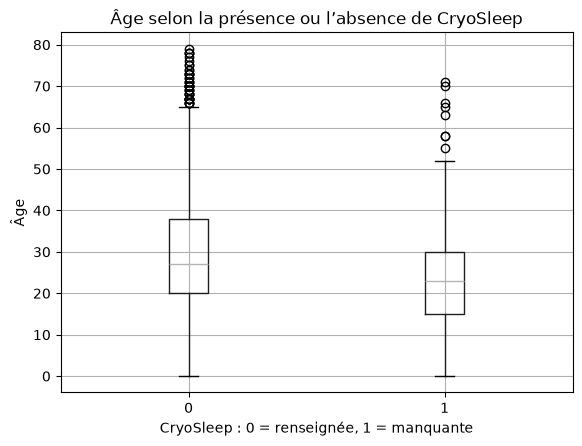

In [43]:
df.boxplot(column="Age", by="CryoSleep_missing")

plt.title("Âge selon la présence ou l’absence de CryoSleep")
plt.suptitle("")
plt.xlabel("CryoSleep : 0 = renseignée, 1 = manquante")
plt.ylabel("Âge")
plt.show()

Le fait que la valeur CryoSleep soit manquante semble relié à l'âge, ce sont plus les jeunes qui présentes des valeurs manquantes. A tester

## 7. Et `RoomService` ?

### Exercice 8

Étudiez `RoomService` :

1. affichez sa distribution parmi les valeurs observées ;
2. comparez quelques variables disponibles entre les lignes où `RoomService` est renseigné et celles où il est manquant ;
3. essayez de déterminer si le mécanisme est MCAR, MAR ou MNAR.

**Question importante :** peut-on savoir, à partir du dataset incomplet uniquement, si l'absence de `RoomService` dépend de la valeur de `RoomService` qui a disparu ?

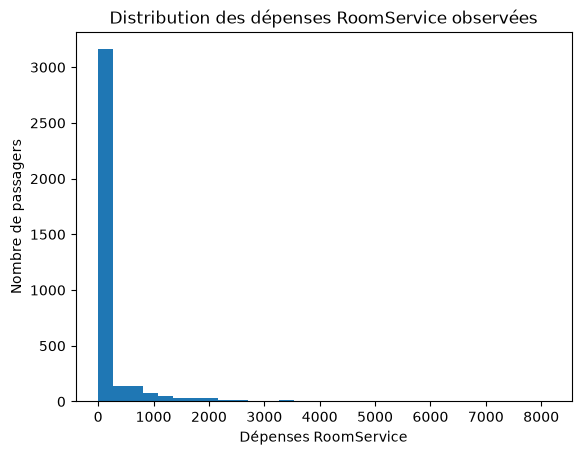

In [44]:
df["RoomService"].dropna().plot(kind="hist", bins=30)

plt.title("Distribution des dépenses RoomService observées")
plt.xlabel("Dépenses RoomService")
plt.ylabel("Nombre de passagers")
plt.show()

Le graphe est biaisé par les valeurs aberrantes (ici les énormes dépenses de très peu de clients)

In [45]:
df.groupby("RoomService_missing")["Age"].agg(["count", "mean", "median"])

,count,mean,median
RoomService_missing,,,
0,3720,28.805108,27.0
1,280,30.307143,27.0


Pas vraiment de lien entre l'âge et les dépenses du room service

In [46]:
df.groupby("CryoSleep")["RoomService_missing"].agg(["count", "mean"])

,count,mean
CryoSleep,,
False,2350,0.098723
True,1330,0.019549


Ici on constate quand même une corrélation entre CryoSleep et la donnée rommservice manquante. On peut donc conclure que la situation MCAR est moins probable car la situation MAR est peut être plausible avec le lien CryoSleep/Age, est il faut examiné si la situation MNAR est possible car sur RoomService le doute est là

## 8. Choisir une stratégie de traitement

On dispose maintenant de trois situations différentes :

| Variable | Mécanisme suspecté | Taux |
|---|---|---:|
| `HomePlanet` | MCAR | ≈ 5 % |
| `CryoSleep` | MAR lié à `Age` | ≈ 8 % |
| `RoomService` | MNAR | ≈ 7 % |

L'objectif n'est pas de trouver une méthode universelle, mais de choisir un traitement cohérent avec chaque situation.

### Exercice 9 — `HomePlanet`

Le taux de valeurs manquantes est faible et le mécanisme est compatible avec MCAR.

1. Combien de lignes seraient perdues si l'on supprimait toutes les lignes où `HomePlanet` est manquant ?
2. Proposez une stratégie simple.
3. Pour la suite du TP, imputez `HomePlanet` par sa modalité la plus fréquente.

200 d'après les premiers exercices

In [47]:
planete_frequente = df["HomePlanet"].mode().iloc[0]
print("Planète la plus fréquente :", planete_frequente)

df["HomePlanet"] = df["HomePlanet"].fillna(planete_frequente)

print("Valeurs encore manquantes :", df["HomePlanet"].isna().sum())

Planète la plus fréquente : Earth
Valeurs encore manquantes : 0


### Exercice 10 — `CryoSleep`

Le mécanisme est compatible avec MAR et semble dépendre de `Age`.

On va utiliser une méthode simple d'**imputation par modèle** :

1. entraînez une régression logistique sur les lignes où `CryoSleep` est connu ;
2. utilisez `Age`, `FoodCourt` et `Spa` comme variables explicatives ;
3. prédisez les valeurs manquantes de `CryoSleep`.

Aucune optimisation du modèle n'est demandée.


In [50]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

variables = ["Age", "FoodCourt", "Spa"]

connues = df["CryoSleep"].notna()
manquantes = df["CryoSleep"].isna()

modele = make_pipeline(
    SimpleImputer(strategy="median"),
    LogisticRegression(max_iter=1000)
)

modele.fit(
    df.loc[connues, variables],
    df.loc[connues, "CryoSleep"].astype(int)
)

predictions = modele.predict(
    df.loc[manquantes, variables]
).astype(bool)

df.loc[manquantes, "CryoSleep"] = predictions

print("Valeurs CryoSleep encore manquantes :", df["CryoSleep"].isna().sum())

Valeurs CryoSleep encore manquantes : 0


### Exercice 11 — `RoomService`

Pour `RoomService`, le mécanisme est suspecté MNAR.

Dans ce cas, l'absence peut elle-même être informative.

1. créez un indicateur `RoomService_missing` ;
2. imputez ensuite les valeurs manquantes avec la médiane observée ;
3. conservez bien l'indicateur dans le dataset.

Pourquoi l'indicateur est-il utile ?

In [53]:
# Crée l'indicateur seulement s'il n'existe pas déjà
if "RoomService_missing" not in df.columns:
    df["RoomService_missing"] = df["RoomService"].isna().astype(int)

# Calcule la médiane des dépenses observées, puis remplace les valeurs manquantes
mediane_roomservice = df["RoomService"].median()
df["RoomService"] = df["RoomService"].fillna(mediane_roomservice)

print("Médiane utilisée :", mediane_roomservice)
print("Valeurs RoomService encore manquantes :", df["RoomService"].isna().sum())
print("Valeurs signalées par l'indicateur :", df["RoomService_missing"].sum())

Médiane utilisée : 0.0
Valeurs RoomService encore manquantes : 0
Valeurs signalées par l'indicateur : 280


L'indicateur renseigne quand même les dépenses qui étaient absentes alors qu'elles ont été remplacées. Cela apporte du coup une information sur le nombre de valeurs manquantes même si elles ne sont plus présentes grâce au modèle.

## 9. Contrôle final du dataset traité

### Exercice 12

1. vérifiez qu'il ne reste plus de valeurs manquantes sur les trois variables étudiées ;
2. comparez rapidement le dataset avant et après traitement ;
3. réfléchissez à ce qui a réellement été « corrigé » et à ce qui reste incertain.

In [52]:
variables = ["HomePlanet", "CryoSleep", "RoomService"]

print("Valeurs manquantes après traitement :")
print(df[variables].isna().sum())

print("\nValeurs initialement manquantes, conservées par les indicateurs :")
print(df[["HomePlanet_missing", "CryoSleep_missing", "RoomService_missing"]].sum())

print("\nNombre de lignes :", len(df))

Valeurs manquantes après traitement :
HomePlanet     0
CryoSleep      0
RoomService    0
dtype: int64

Valeurs initialement manquantes, conservées par les indicateurs :
HomePlanet_missing     200
CryoSleep_missing      320
RoomService_missing    280
dtype: int64

Nombre de lignes : 4000


Il n'y a donc plus de valeurs manquantes. Aucunes lignes supprimées, mais les valeurs manquantes n'ont pas été retrouvées de façon certaine. Les valeurs imputées sont des estimations.

## 10. Synthèse

À retenir :

1. **ne pas commencer par imputer** ;
2. quantifier et visualiser les absences ;
3. créer des indicateurs de manque et rechercher des relations ;
4. comparer les observations complètes et incomplètes ;
5. raisonner en termes de **MCAR / MAR / MNAR** ;
6. choisir un traitement adapté au mécanisme et à l'usage ;
7. vérifier autant que possible l'effet du traitement sur les données.
